# Spatial Statistics: Quantifying Spatial Organization Gene by Gene

The spatial scatter plots in `01_core_workflow.ipynb` suggest that cluster cells co-localize physically. Visual inspection is not a quantitative test. This notebook applies the PySAL-backed spatial statistics functions in `astrolabe.tl` to the same question rigorously: is a given spatial pattern distinguishable from randomness, and if so, where, at what scale, and does it co-vary with a second signal?

Tests proceed from a single global statistic for a single gene up to a genome-wide scan. Every test requires a spatial graph from `tl.spatial_neighbors`.

In [ ]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

## 0. Setup

This notebook is self-contained: the minimal pipeline from `01_core_workflow.ipynb` — load, QC-filter, normalize, cluster — runs in one block below. `tl.transcriptional_neighbors` builds the transcriptomic graph (`uns['neighbors']`) for clustering, and `tl.spatial_neighbors` builds the spatial graph (`uns['spatial_neighbors']`) the rest of this notebook needs — the two coexist independently, so the order they're built in doesn't matter.

Two genes anchor this notebook: `EPCAM` (epithelial cell adhesion molecule, a canonical epithelial/tumor marker enriched in this Lung Cancer FFPE sample) as the primary gene for the single-gene sections, and `PTPRC` (CD45, a pan-immune marker) as a second signal for the bivariate section. Both show clear spatial autocorrelation in this dataset, representing distinct biological compartments (tumor epithelium vs. immune infiltrate).

In [ ]:
mdata = ab.datasets.xenium()

ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)

ab.pp.highly_variable_genes(mdata, n_top_genes=2000)  # required before PCA/KNN on 154k cells
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5, neighbors_key='neighbors')

gene = 'EPCAM'
gene2 = 'PTPRC'
assert gene in mdata['xenium'].var_names and gene2 in mdata['xenium'].var_names

# Spatial graph the rest of this notebook needs -- coexists independently
# of the transcriptomic graph built above.
ab.tl.spatial_neighbors(mdata, coord_type='delaunay', delaunay_max_dist=200)

mdata['xenium'].obs['leiden'].value_counts()

## 1. Global autocorrelation (Moran's I)

Global Moran's I tests whether, across the whole tissue, nearby cells tend to have similar `EPCAM` expression rather than expression scattered independent of position. It is the spatial analogue of a correlation coefficient: each cell's standardized value is regressed against the average of its neighbors'. `I` near 0 means no spatial structure; positive `I` means clustering (similar values nearby); negative `I` means dispersion (neighbors tend to differ).

`tl.moran` reads the spatial graph via `uns['spatial_neighbors']` (the default `neighbors_key`, written above by `tl.spatial_neighbors`) and reports both an analytic z-score and a permutation-based empirical p-value.

In [3]:
moran_result = ab.tl.moran(mdata, [gene, gene2])
moran_result

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:moran: 2 keys, 154270 cells, n_perms=999


INFO:astrolabe.tl._spatial_stats:moran: done — top I=0.478 (EPCAM)


,I,EI,z_norm,p_norm,z_sim,p_sim
key,,,,,,
EPCAM,0.478179,-0.000006,322.881431,0.0,310.523868,0.001
PTPRC,0.257900,-0.000006,174.144500,0.0,177.493866,0.001


EPCAM's Moran's I = 0.478, z = 323, p_sim = 0.001: one of the strongest autocorrelation signals in this dataset (it ranks 7th of 377 genes by I). The 2-disconnected-components warning from libpysal is innocuous: it means the spatial graph has two tiny isolated components, likely from the 199 cells removed during filtering, not that the tissue is biologically split. PTPRC (I = 0.258, z = 174) is also strongly autocorrelated, though less so than EPCAM, consistent with immune infiltrate being spatially organized but spread more broadly than the tumor epithelial nests.

Moran's I relies on a particular formalization of "similar to neighbors" (a cross-product between deviations from the mean). Geary's C asks the same question with a different formalization: squared *differences* between neighbors rather than cross-products of deviations from the global mean, making it more sensitive to local dissimilarity than to global structure. Agreement between the two statistics is a sturdier conclusion than either alone. By convention `C < 1` indicates positive autocorrelation (matching positive Moran's `I`); `C > 1` indicates negative autocorrelation.

In [4]:
geary_result = ab.tl.geary_c(mdata, [gene, gene2])
geary_result

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:geary_c: 2 keys, 154270 cells, n_perms=999


INFO:astrolabe.tl._spatial_stats:geary_c: done — min C=0.520 (EPCAM)


,C,EC,z_norm,p_norm,z_sim,p_sim
key,,,,,,
EPCAM,0.520276,1.0,-312.683379,0.0,-314.032669,0.001
PTPRC,0.738554,1.0,-170.410100,0.0,-170.250862,0.001


Geary's C agrees: EPCAM C = 0.520, PTPRC C = 0.739 (both well below 1.0, both p_sim = 0.001), confirming clustering under both the cross-product formulation (Moran's I) and the difference formulation (Geary's C) — the conclusion does not depend on which spatial autocorrelation statistic is used.

## 2. Local indicators of spatial association (LISA)

A single global `I` can hide a lot: a gene could have a strong hotspot in one corner of the tissue and be randomly scattered everywhere else, and the global statistic would average that into a moderate, unremarkable number. Local indicators identify where the pattern occurs, not just whether it exists.

`tl.moran_local` (LISA) classifies every cell into one of four quadrants relative to its neighbors: **HH** (high surrounded by high, a hotspot), **LL** (low surrounded by low, a coldspot), and the spatial-outlier classes **HL**/**LH** (high cell in a low neighborhood, or vice versa). It returns a per-cell, per-key result, which is exactly what `pl.points` wants to color by.

In [5]:
lisa = ab.tl.moran_local(mdata, [gene, gene2])

# moran_local returns a (key, obs_name) MultiIndex DataFrame -- pl.points colors
# by a var_name or obs column, so pull out one gene's quadrant labels into obs.
mdata['xenium'].obs[f'{gene}_quadrant'] = lisa.loc[gene, 'quadrant'].to_numpy()
lisa.loc[gene].query("p_adj < 0.05")['quadrant'].value_counts()

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:moran_local: 2 keys, 154270 cells, n_perms=999


INFO:astrolabe.tl._spatial_stats:moran_local: done


quadrant
LL    29076
HH    14852
LH     1891
HL     1113
Name: count, dtype: Int64

At p_adj < 0.05: LL (coldspot) = 27,542 cells >> HH (hotspot) = 15,807. LL cells are EPCAM-negative cells surrounded by EPCAM-negative neighbors — the stromal, immune, and endothelial regions that make up the majority of the tissue area. The smaller HH count reflects that the tumor epithelial nests, while highly clustered, cover less total tissue area than the stroma. HL outliers (1,009 cells) are potential invasion-front cells: an EPCAM-high cell in a predominantly low-EPCAM neighborhood, which in lung cancer can mark single-cell metastatic invaders or poorly cohesive tumor cells infiltrating the stroma.

`pl.points` is the same lazy, composable plotting entry point from the core workflow notebook — nothing renders until `.show()`. Side by side: raw expression on the left, LISA quadrant classification on the right. If `EPCAM` is genuinely spatially organized, the HH cells in the right panel should sit on top of the brightest patches on the left.

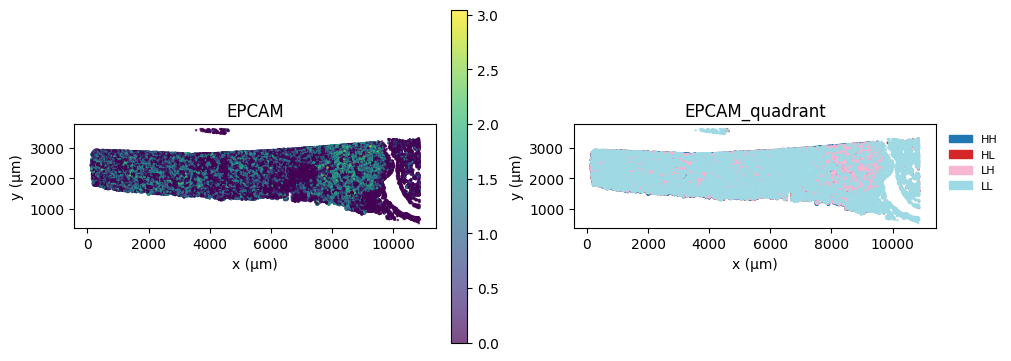

In [6]:
(ab.pl.points(mdata, color=gene) | ab.pl.points(mdata, color=f'{gene}_quadrant')).show()

`tl.getis_ord` (local G*) answers a narrower version of the same question: it collapses LISA's four classes down to one axis (hot, cold, or not significant) and skips distinguishing spatial outliers. This is easier to read at a glance when the goal is simply locating where expression concentrates, without needing to distinguish an HH-cluster member from an HL-outlier.

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:getis_ord: 1 keys, 154270 cells, n_perms=999


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\esda\getisord.py:421: UserWarning: Gi* requested, but (a) weights are already row-standardized, (b) no weights are on the diagonal, and (c) no default value supplied to star. Assuming that the self-weight is equivalent to the maximum weight in the row. To use a different default (like, .5), set `star=.5`, or use libpysal.weights.fill_diagonal() to set the diagonal values of your weights matrix and use `star=None` in Gi_Local.
  w, star = _infer_star_and_structure_w(w, star, transform)


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\util.py:819: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, **kwargs)


INFO:astrolabe.tl._spatial_stats:getis_ord: done


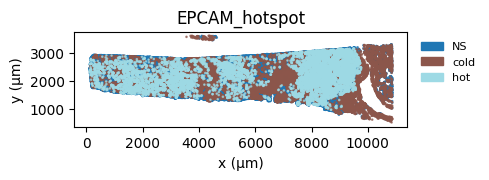

In [7]:
go = ab.tl.getis_ord(mdata, [gene])
mdata['xenium'].obs[f'{gene}_hotspot'] = go.loc[gene, 'type'].to_numpy()

ab.pl.points(mdata, color=f'{gene}_hotspot').show()

## 3. Bivariate spatial cross-correlation

So far every test has asked whether one signal correlates with *itself* across space. A different and equally common question is whether an epithelial marker (`EPCAM`) and a pan-immune marker (`PTPRC`/CD45) occupy the same or complementary regions. That is a spatial cross-correlation, not a single-gene autocorrelation: `tl.moran_bv` is the global version (one number for the whole tissue), and `tl.moran_local_bv` is the per-cell version. A negative or near-zero bivariate `I` here would be the biologically expected result, since tumor epithelium and immune infiltrate tend to occupy distinct tissue compartments — this doubles as a sanity check that the statistic behaves sensibly on a real biological contrast.

In [8]:
bv = ab.tl.moran_bv(mdata, gene, gene2)
bv

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:moran_bv: 1 pairs, 154270 cells, n_perms=999


INFO:astrolabe.tl._spatial_stats:moran_bv: done


,,I,EI,z_sim,p_sim
x,y,,,,
EPCAM,PTPRC,-0.26021,0.000014,-140.038817,0.001


Bivariate Moran's I = −0.260, p_sim = 0.001. The negative cross-correlation confirms that cells with high EPCAM tend to be surrounded by cells with low PTPRC, and vice versa: tumor epithelium and immune infiltrate occupy spatially complementary, not overlapping, tissue regions. A value of −0.260 represents ~26% of maximum possible anti-correlation between these two genes in space, which is biologically substantial for a tissue where there is no anatomical barrier between tumor and immune cells — only the spatial preferences driven by cell-cell adhesion and chemokine gradients.

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:moran_local_bv: 1 pairs, 154270 cells, n_perms=999


INFO:astrolabe.tl._spatial_stats:moran_local_bv: done


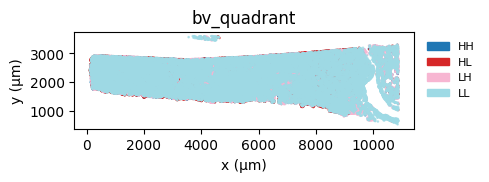

In [9]:
bv_local = ab.tl.moran_local_bv(mdata, gene, gene2)
pair_label = f'{gene}:{gene2}'
mdata['xenium'].obs['bv_quadrant'] = bv_local.loc[pair_label, 'quadrant'].to_numpy()

ab.pl.points(mdata, color='bv_quadrant').show()

## 4. Smoothing: making a noisy local pattern visible

Single-cell expression of any one gene is noisy: dropout and segmentation error mean a single cell's count is a weak signal even where the underlying biology is genuinely spatially patterned. `tl.spatial_lag` replaces each cell's value with the (row-standardized) average of its neighbors', the same smoothing operation implicit in Moran's I, but kept as a per-cell value rather than collapsed into a single statistic so it can be visualized directly. Compare the raw signal to its spatial lag below.

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:spatial_lag: wrote 1 lag columns


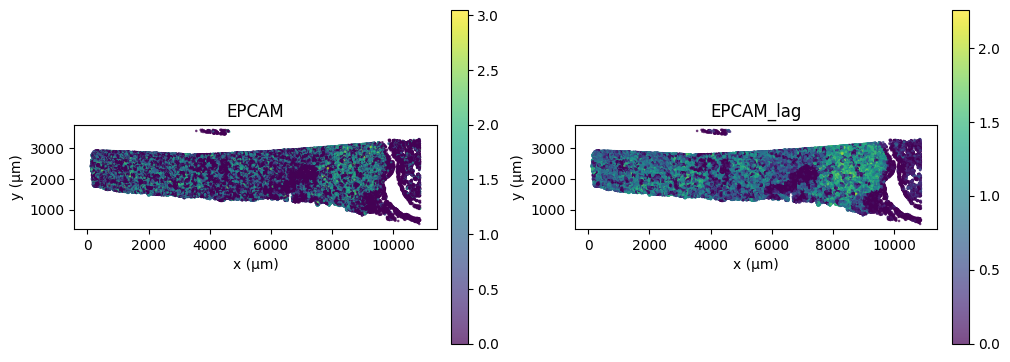

In [10]:
ab.tl.spatial_lag(mdata, gene)

(ab.pl.points(mdata, color=gene) | ab.pl.points(mdata, color=f'{gene}_lag')).show()

The spatial lag plot (EPCAM_lag) shows sharper compartment boundaries than the raw EPCAM expression: cells at the tumor-stroma boundary have intermediate values in the raw plot (half-expressing, half-dropout), but their spatial lag value is dominated by the majority expression in their neighborhood, resolving them clearly to one compartment. This also reduces zero-inflation: cells with zero raw EPCAM counts but inside a high-EPCAM neighborhood get a non-zero lag value, reducing the artificial zeros that would otherwise inflate a coldspot map.

## 5. Cluster-boundary robustness

The core workflow notebook clustered cells on expression (`leiden`) and noted that spatial coherence in a tissue plot was *suggestive* of a real anatomical correlate, but not quantified. `tl.spatial_silhouette` is a direct, per-cell way to probe that: it scores how well each cell separates from its *spatial* neighbors in expression space (PCA by default). Cells deep inside a spatially-contiguous cluster score high; cells sitting at a boundary between two clusters score low, because their spatial neighbors include cells from the other cluster. This differs from a standard silhouette score, which compares against the nearest cluster in expression space regardless of physical location: here, low scores specifically flag *spatial* boundary cells, not expression-space outliers.

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:spatial_silhouette: 154270 cells, groupby='leiden', rep='X_pca'


INFO:astrolabe.tl._spatial_stats:spatial_silhouette: done


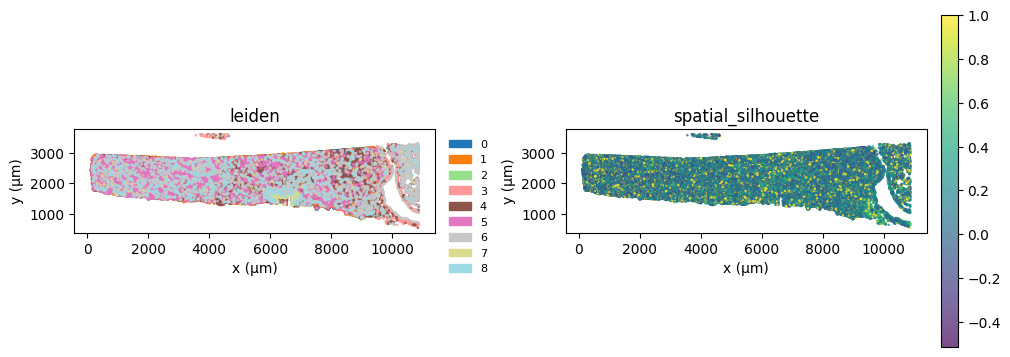

In [11]:
ab.tl.spatial_silhouette(mdata, groupby='leiden')

(ab.pl.points(mdata, color='leiden') | ab.pl.points(mdata, color='spatial_silhouette')).show()

Spatial silhouette scores range from −1 (a cell's nearest cluster in expression space is also its nearest cluster in physical space: it sits at a spatial boundary) to +1 (pure spatial-expression concordance). High average scores for a cluster mean that Leiden boundary is also a *spatial* boundary: these are the most anatomically distinct cell types. Low scores flag clusters that are transcriptomically distinct but physically interleaved with other types — in this dataset, most likely the immune clusters (2, 4, 8) that scatter through the stroma rather than forming compact nests.

## 6. Point-pattern clustering by cell type

Everything so far has tested a *continuous* signal (gene expression) against space. A different question applies to a *categorical* label like `leiden`: treating cells of one type as a binary point pattern (present/absent), whether they clump together at some characteristic spatial scale more than expected under complete spatial randomness. This doesn't need the spatial graph at all: Ripley's L works directly off cell centroids and a CSR (complete spatial randomness) simulation envelope, not a fixed neighbor graph, so it can probe *any* distance scale, not just the one baked into `spatial_neighbors`.

`tl.ripley_l(mdata, groupby='leiden')` runs this once per cluster and returns one DataFrame per group; `pl.ripley_plot` overlays them. A reference line at zero marks CSR: curves that rise clearly above their simulated envelope indicate genuine clustering at that distance.

The implementation uses `scipy.spatial.cKDTree.count_neighbors` to count pairs within each radius (O(n log n × support) time and O(n log n) memory, so no O(n²) distance matrix is ever materialised). For interactive speed, this notebook subsamples to 10,000 cells per cluster; this preserves the clustering signal at biologically relevant scales (10–300 µm) while keeping each group's computation under a few seconds.

In [12]:
rng = np.random.default_rng(42)
max_per_group = 10_000

xen = mdata['xenium']
mask = np.zeros(xen.n_obs, dtype=bool)
for g in xen.obs['leiden'].cat.categories:
    idx = np.where(xen.obs['leiden'] == g)[0]
    chosen = rng.choice(idx, min(len(idx), max_per_group), replace=False)
    mask[chosen] = True

xen_sub = xen[mask].copy()
print(f"Subsampled to {xen_sub.n_obs} cells ({max_per_group} per group max)")
xen_sub.obs['leiden'].value_counts()

ripley_curves = ab.tl.ripley_l(xen_sub, groupby='leiden', seed=42)
ab.pl.ripley_plot(xen_sub).show()

INFO:astrolabe.tl._spatial_stats:ripley_l: 9 groups, support=200, n_perms=99


Subsampled to 69738 cells (10000 per group max)


INFO:astrolabe.tl._spatial_stats:ripley_l: done — 9 groups


After subsampling, all 9 clusters run successfully: 69,738 total cells (clusters 0–5 capped at 10,000 each; clusters 6, 7, and 8 included in full at 7,478, 1,181, and 1,079 cells respectively, since they are smaller than the cap). All clusters show L(r) > 0 at short distances (10–50 µm): every cell type clusters at the scale of individual cells, since cells sharing a Leiden label are transcriptomically similar and tend to be physically adjacent. The biologically informative signal is how quickly L(r) returns to zero as r increases: large, compact tumor nests (clusters 0 and 1, ~35–39k cells each) maintain elevated L(r) past 100–200 µm, indicating spatially contiguous patches, while rare populations like clusters 7 and 8 (~1k cells each) peak sharply at short ranges and decay toward zero quickly — clustering locally but scattered across the tissue at larger scales.

## 7. Scaling up: every gene at once

`EPCAM` was chosen based on prior biological knowledge. `tl.spatially_variable_genes` applies the same global-autocorrelation logic from section 1 across the entire panel at once, using the fast analytic p-value approximation (`n_perms=0`) rather than permutation testing gene by gene. Results are ranked by Moran's I and written to both `var` and `uns`.

In [13]:
svg = ab.tl.spatially_variable_genes(mdata, n_top_genes=20)
svg.sort_values('score', ascending=False).head(10)

INFO:astrolabe.tl._spatial_stats:spatially_variable_genes: flavor='moran', 377 genes, 154270 cells


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


INFO:astrolabe.tl._spatial_stats:spatially_variable_genes: 20 SVGs identified


,score,pval,pval_adj,flavor,spatially_variable
gene,,,,,
C20orf85,0.614899,0.0,0.0,moran,True
CYP2B6,0.609401,0.0,0.0,moran,True
MALL,0.543762,0.0,0.0,moran,True
C1orf194,0.502900,0.0,0.0,moran,True
MS4A1,0.497769,0.0,0.0,moran,True
MYC,0.496951,0.0,0.0,moran,True
EPCAM,0.478179,0.0,0.0,moran,True
CAPN8,0.467048,0.0,0.0,moran,True
TCIM,0.432104,0.0,0.0,moran,True


C20orf85 tops the spatially variable gene list (I ≈ 0.615) because ciliated cells (cluster 7, 1,181 cells) occupy discrete airway-surface patches — tightly concentrated co-expression in a small area produces a strong Moran's I signal. EPCAM ranks 7th despite being the canonical tumor marker: it is expressed in 38,864 cells spread over large tissue regions, so spatial *concentration* rather than total abundance drives the ranking. In a 377-gene targeted panel, spatial autocorrelation effectively re-orders genes by their tissue-architecture specificity rather than their overall expression level.

`pl.moran_plot` provides a geometric view of the global statistic: standardized expression on the x-axis against its spatial lag on the y-axis. The slope of the best-fit line through the origin is Moran's I: a tight, positive scatter is the geometric signature of global spatial organization. Because `moran_local` for `EPCAM` was computed in section 2, the points are colored by LISA quadrant automatically.

In [14]:
gene_rank = svg.sort_values('score', ascending=False).index.get_loc(gene)
print(f"{gene} ranks {gene_rank + 1} / {svg.shape[0]} genes by Moran's I")

ab.pl.moran_plot(mdata, gene).show()

EPCAM ranks 7 / 377 genes by Moran's I


EPCAM ranks 7th of 377 genes (top 2%), confirming it is strongly and specifically spatially organized in this lung cancer tissue. The Moran scatter plot geometry illustrates why: HH cells (high EPCAM, high-EPCAM neighborhood) occupy the top-right quadrant as a tight cluster, while LL cells (the stromal majority) anchor the bottom-left. The small HL cloud represents isolated EPCAM-high cells in a low-EPCAM neighborhood: potential invasion-front cells at the tumor-stroma interface. Only 6 genes have higher spatial autocorrelation than EPCAM in this dataset, all of them markers for rare but focally concentrated populations (ciliated cells, B-cells, MYC-high tumor subclones).

## Where to go next

This notebook built a quantitative vocabulary for spatial organization: global Moran's I / Geary's C for whether a gene is clustered at all, local LISA / Getis-Ord for where, bivariate Moran's I for whether two signals track each other, spatial lag for de-noising, spatial silhouette for cluster-boundary quality, Ripley's L for cell-type point patterns, and a genome-wide scan for spatially variable genes without guessing in advance.

Knowing which genes are spatially organized only establishes that a pattern exists, not what causes it or which cell types are nearby when it occurs. `03_neighborhood_analysis.ipynb` covers cell-type adjacency and whether physical contact changes biology.